In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import scipy.stats as stats
import seaborn as sns

In [2]:
ds = xr.open_dataset('merged_cams_era5_data.nc')


   id                    Name
0   1         Coastal savanna
1   2           Wet evergreen
2   3         Moist evergreen
3   5         Decidous forest
4   4       Transitional zone
5   6          Guinea savanna
6   7           Sudan savanna
7   8  Waterbody - Volta lake


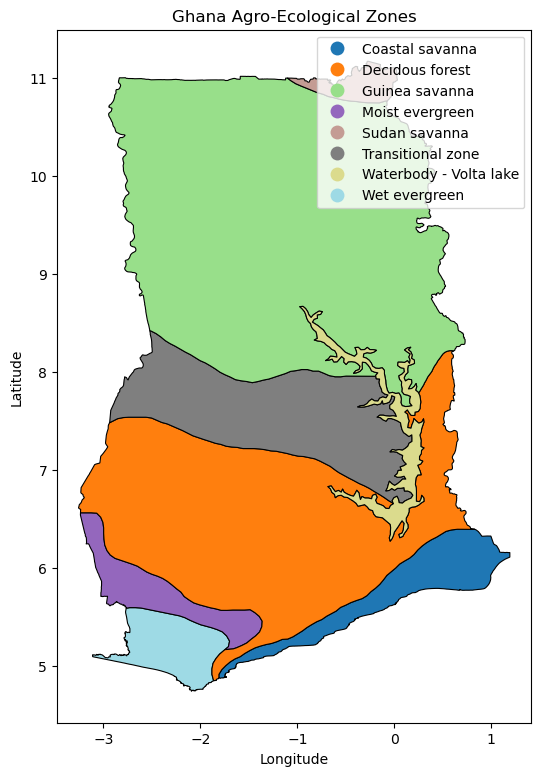

In [3]:
ghana_aez = gpd.read_file('ghanaAEZ.geojson')

# It is already EPSG:4326, but this ensures compatibility with NetCDF coordinates.
ghana_aez = ghana_aez.to_crs(epsg=4326)

print(ghana_aez[["id", "Name"]])

fig, ax = plt.subplots(figsize=(8, 9))

ghana_aez.plot(
    ax=ax,
    column="Name",
    cmap="tab20",
    edgecolor="black",
    linewidth=0.8,
    legend=True
)

ax.set_title("Ghana Agro-Ecological Zones")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

In [4]:
# Combine all agroecological-zone polygons
ghana_boundary = ghana_aez.geometry.union_all()

print("Combined boundary type:", ghana_boundary.geom_type)
print("Ghana boundary:", ghana_boundary.bounds)

Combined boundary type: Polygon
Ghana boundary: (-3.255419797781921, 4.739103942861226, 1.191768793191243, 11.173299998730634)


In [5]:
# Create a grid of latitude and longitude points
lon2d, lat2d = np.meshgrid(ds.longitude.values, ds.latitude.values)

# Convert grid points into a GeoDataFrame
grid_points = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        lon2d.ravel(),
        lat2d.ravel()
    ),
    crs=ghana_aez.crs
)

# Identify grid points within Ghana's agroecological zones
ghana_points = gpd.sjoin(
    grid_points,
    ghana_aez[['geometry']],
    how='inner',
    predicate='intersects'
)

# Create a Boolean spatial mask
mask = np.zeros(len(grid_points), dtype=bool)
mask[ghana_points.index.unique()] = True

mask = mask.reshape(len(ds.latitude), len(ds.longitude))

# Convert the mask into an Xarray DataArray
ghana_mask = xr.DataArray(
    mask,
    coords={
        'latitude': ds.latitude,
        'longitude': ds.longitude
    },
    dims=['latitude', 'longitude']
)

print("Grid points inside Ghana:", mask.sum())
print("Total grid points:", mask.size)

Grid points inside Ghana: 309
Total grid points: 609


In [7]:
# Apply the Ghana mask to the NetCDF dataset
ds_ghana = ds[['pm2p5', 'pm10', 'ssr']].where(ghana_mask)


In [8]:
# Select data for 2022
ds_ghana_2022 = ds_ghana.sel(
    valid_time=slice('2022-01-01', '2022-12-31')
)



In [9]:
# Calculate spatial averages over Ghana
ghana_hourly = ds_ghana_2022.mean(
    dim=["latitude", "longitude"],
    skipna=True
)


In [10]:
# Convert to DataFrame
df_hourly = ghana_hourly.to_dataframe().reset_index()

# Display first five rows
df_hourly.head()

,valid_time,pm2p5,pm10,ssr,number,expver
0,2022-01-01 00:00:00,8.459740e-08,1.128506e-07,3.599999e-12,0,0001
1,2022-01-01 01:00:00,NaN,NaN,3.599999e-12,0,0001
2,2022-01-01 02:00:00,NaN,NaN,3.599999e-12,0,0001
3,2022-01-01 03:00:00,7.896579e-08,1.050749e-07,3.599999e-12,0,0001
4,2022-01-01 04:00:00,NaN,NaN,3.599999e-12,0,0001


In [12]:
# Calculate monthly averages
ghana_monthly = ghana_hourly.resample(
    valid_time="MS"
).mean(skipna=True)

In [13]:
# Convert monthly dataset to DataFrame
df_monthly = ghana_monthly.to_dataframe().reset_index()

# Display first 12 rows
df_monthly.head(12)

,valid_time,pm2p5,pm10,ssr,number
0,2022-01-01,1.062739e-07,1.395590e-07,768940.0625,0
1,2022-02-01,8.698849e-08,1.073632e-07,773900.3125,0
2,2022-03-01,6.256889e-08,7.704139e-08,755914.0625,0
3,2022-04-01,2.915310e-08,3.774765e-08,716478.5625,0
4,2022-05-01,2.780800e-08,3.736857e-08,696702.2500,0
5,2022-06-01,1.928339e-08,2.670324e-08,599715.8750,0
6,2022-07-01,1.917349e-08,2.694361e-08,566589.4375,0
7,2022-08-01,1.785674e-08,2.516991e-08,543384.6875,0
8,2022-09-01,1.740494e-08,2.453702e-08,537891.8750,0
9,2022-10-01,2.991990e-08,4.033807e-08,681248.5000,0


In [14]:
df_monthly["Year"] = df_monthly["valid_time"].dt.year

df_monthly["Month"] = df_monthly["valid_time"].dt.month

df_monthly["Month_Name"] = df_monthly["valid_time"].dt.month_name()

df_monthly.head(12)

,valid_time,pm2p5,pm10,ssr,number,Year,Month,Month_Name
0,2022-01-01,1.062739e-07,1.395590e-07,768940.0625,0,2022,1,January
1,2022-02-01,8.698849e-08,1.073632e-07,773900.3125,0,2022,2,February
2,2022-03-01,6.256889e-08,7.704139e-08,755914.0625,0,2022,3,March
3,2022-04-01,2.915310e-08,3.774765e-08,716478.5625,0,2022,4,April
4,2022-05-01,2.780800e-08,3.736857e-08,696702.2500,0,2022,5,May
5,2022-06-01,1.928339e-08,2.670324e-08,599715.8750,0,2022,6,June
6,2022-07-01,1.917349e-08,2.694361e-08,566589.4375,0,2022,7,July
7,2022-08-01,1.785674e-08,2.516991e-08,543384.6875,0,2022,8,August
8,2022-09-01,1.740494e-08,2.453702e-08,537891.8750,0,2022,9,September
9,2022-10-01,2.991990e-08,4.033807e-08,681248.5000,0,2022,10,October


In [15]:
# Convert kg/m3 to µg/m3

df_monthly["pm2p5_ugm3"] = df_monthly["pm2p5"] * 1e9

df_monthly["pm10_ugm3"] = df_monthly["pm10"] * 1e9

# Display converted values
df_monthly[[
    "Month_Name",
    "pm2p5_ugm3",
    "pm10_ugm3"
]]

,Month_Name,pm2p5_ugm3,pm10_ugm3
0,January,106.273923,139.558992
1,February,86.988493,107.363185
2,March,62.568887,77.041392
3,April,29.153103,37.747647
4,May,27.808005,37.368565
5,June,19.283389,26.703242
6,July,19.173491,26.943612
7,August,17.856742,25.169911
8,September,17.404941,24.537018
9,October,29.919899,40.338065


In [16]:
df_monthly["ssr_wm2"] = df_monthly["ssr"] / 3600
df_monthly[["Month_Name", "ssr", "ssr_wm2"]]

,Month_Name,ssr,ssr_wm2
0,January,768940.0625,213.594462
1,February,773900.3125,214.972309
2,March,755914.0625,209.976128
3,April,716478.5625,199.021823
4,May,696702.2500,193.528403
5,June,599715.8750,166.587743
6,July,566589.4375,157.385955
7,August,543384.6875,150.940191
8,September,537891.8750,149.414410
9,October,681248.5000,189.235694


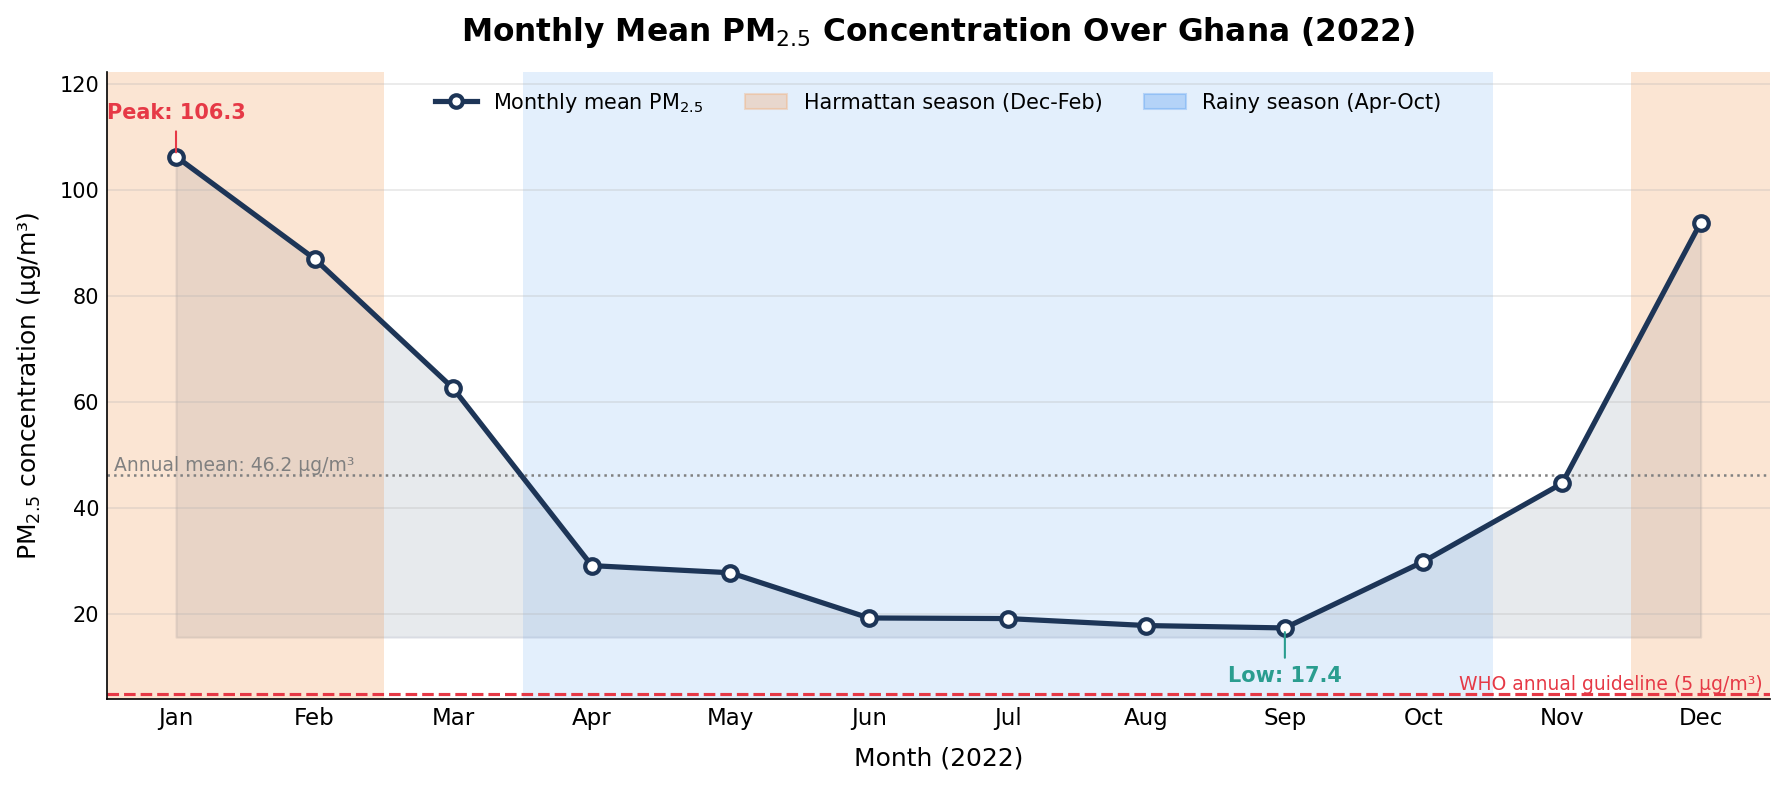

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# --- Data ---
x = np.arange(len(df_monthly))
months = df_monthly["Month_Name"].astype(str).str[:3]
y = df_monthly["pm2p5_ugm3"].values

# --- Style ---
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

fig, ax = plt.subplots(figsize=(12, 5.5), dpi=150)

# Harmattan season shading (Dec-Feb), assumes data runs Jan-Dec
ax.axvspan(-0.5, 1.5, color="#f4a261", alpha=0.15, lw=0)
ax.axvspan(10.5, 11.5, color="#f4a261", alpha=0.15, lw=0)

# Main line + area fill
ax.plot(x, y, color="#1d3557", linewidth=2.5, marker="o",
        markersize=7, markerfacecolor="white", markeredgewidth=2, zorder=3)
ax.fill_between(x, y, y.min() * 0.9, color="#1d3557", alpha=0.10)

# Axis limits first, so reference lines can be checked against them
ymin, ymax = min(y.min(), 5) * 0.8, y.max() * 1.15
ax.set_ylim(ymin, ymax)

# WHO 2021 annual guideline (5 µg/m³), drawn only if within range
if ymin < 5 < ymax:
    ax.axhline(5, color="#e63946", linestyle="--", linewidth=1.5, zorder=2)
    ax.text(len(x) - 0.55, 5, "WHO annual guideline (5 µg/m³)",
            color="#e63946", va="bottom", ha="right", fontsize=9)

# Annual mean line
ax.axhline(y.mean(), color="gray", linestyle=":", linewidth=1.2)
ax.text(-0.45, y.mean(), f"Annual mean: {y.mean():.1f} µg/m³",
        color="gray", va="bottom", fontsize=9)

# Peak and minimum annotations
imax, imin = y.argmax(), y.argmin()
ax.annotate(f"Peak: {y[imax]:.1f}", (x[imax], y[imax]),
            xytext=(0, 18), textcoords="offset points", ha="center",
            fontsize=10, fontweight="bold", color="#e63946",
            arrowprops=dict(arrowstyle="-", color="#e63946"))
ax.annotate(f"Low: {y[imin]:.1f}", (x[imin], y[imin]),
            xytext=(0, -26), textcoords="offset points", ha="center",
            fontsize=10, fontweight="bold", color="#2a9d8f",
            arrowprops=dict(arrowstyle="-", color="#2a9d8f"))

# Axes formatting
ax.set_xticks(x)
ax.set_xticklabels(months, fontsize=11)
ax.set_xlim(-0.5, len(x) - 0.5)
ax.set_xlabel("Month (2022)", fontsize=12, labelpad=8)
ax.set_ylabel("PM$_{2.5}$ concentration (µg/m³)", fontsize=12, labelpad=8)
ax.set_title("Monthly Mean PM$_{2.5}$ Concentration Over Ghana (2022)",
             fontsize=15, pad=15)
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="both", length=0)

# Legend
harmattan = mpatches.Patch(color="#f4a261", alpha=0.3, label="Harmattan season (Dec-Feb)")
rainy = mpatches.Patch(color="#4895ef", alpha=0.3, label="Rainy season (Apr-Oct)")
line_handle = plt.Line2D([0], [0], color="#1d3557", marker="o", markerfacecolor="white",
                         markeredgewidth=2, linewidth=2.5, label="Monthly mean PM$_{2.5}$")
# Harmattan season shading (Dec-Feb)
ax.axvspan(-0.5, 1.5, color="#f4a261", alpha=0.15, lw=0)
ax.axvspan(10.5, 11.5, color="#f4a261", alpha=0.15, lw=0)

# Rainy season shading (Apr-Oct)
ax.axvspan(2.5, 9.5, color="#4895ef", alpha=0.15, lw=0)
ax.legend(handles=[line_handle, harmattan, rainy], loc="upper center",
          ncol=3, frameon=False, fontsize=10)

plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig("pm25_monthly_ghana_2022.png", dpi=300, bbox_inches="tight")
plt.show()

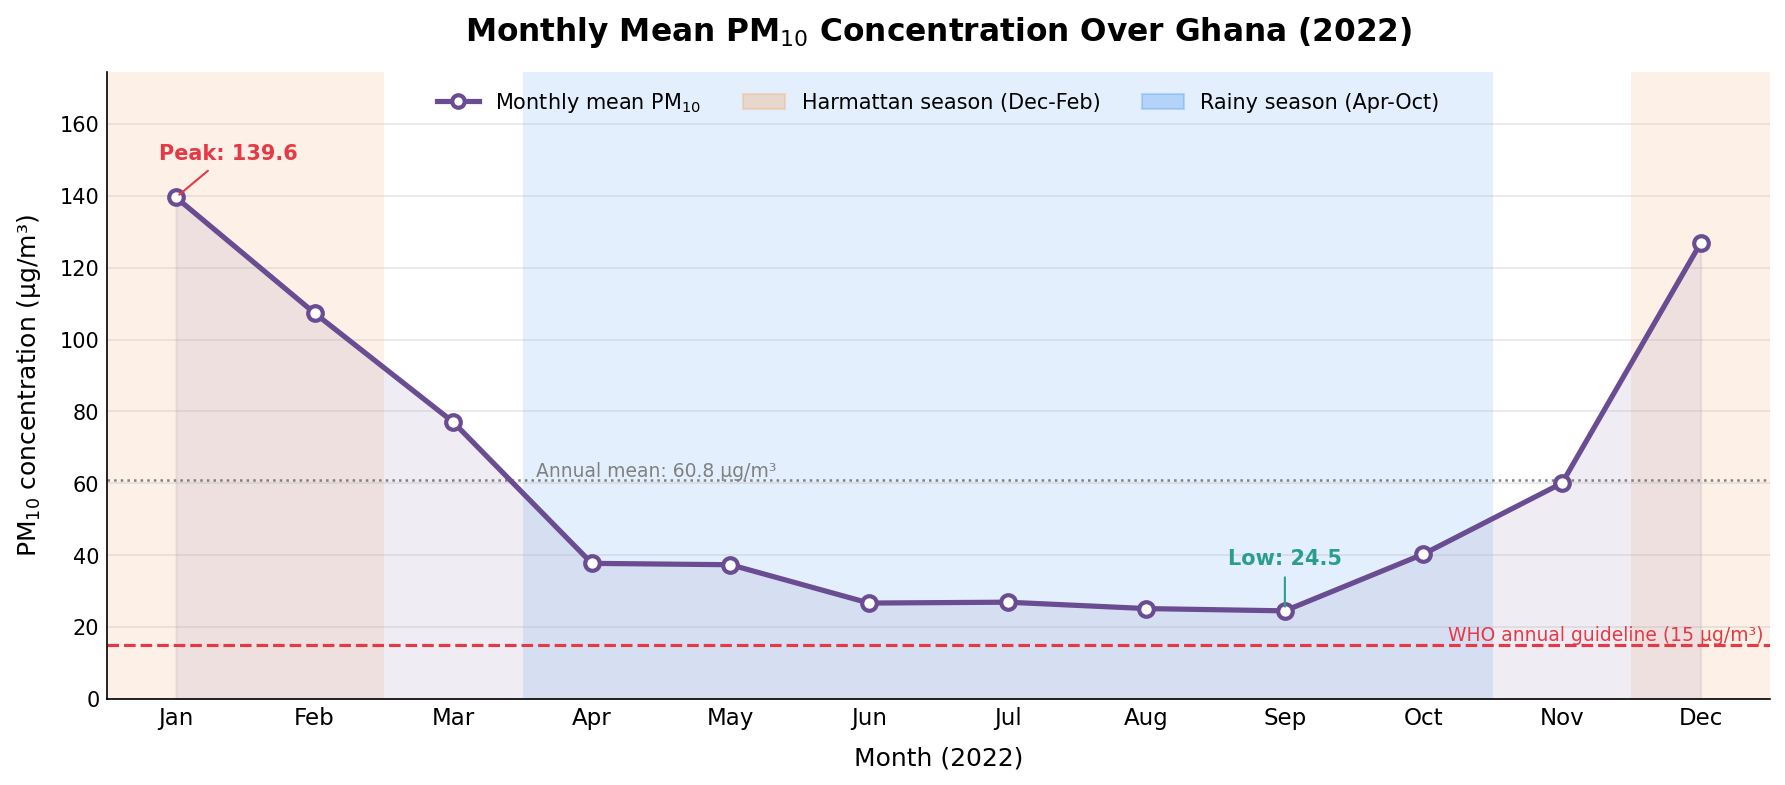

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

def plot_monthly_pm(df, col, label, who_limit, color, fname):
    x = np.arange(len(df))
    months = df["Month_Name"].astype(str).str[:3]
    y = df[col].values

    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
    })
    fig, ax = plt.subplots(figsize=(12, 5.5), dpi=150)

    # Season shading (assumes data runs Jan-Dec)
    ax.axvspan(-0.5, 1.5, color="#f4a261", alpha=0.15, lw=0)    # Harmattan Jan-Feb
    ax.axvspan(10.5, 11.5, color="#f4a261", alpha=0.15, lw=0)   # Harmattan Dec
    ax.axvspan(2.5, 9.5, color="#4895ef", alpha=0.15, lw=0)     # Rainy Apr-Oct

    # Axis limits (start at 0 so the WHO line is visible)
    ymax = y.max() * 1.25
    ax.set_ylim(0, ymax)

    # Main line + fill
    ax.plot(x, y, color=color, linewidth=2.5, marker="o", markersize=7,
            markerfacecolor="white", markeredgewidth=2, zorder=3)
    ax.fill_between(x, y, 0, color=color, alpha=0.10)

    # WHO guideline, drawn only if inside the axis range
    if 0 < who_limit < ymax:
        ax.axhline(who_limit, color="#e63946", linestyle="--", linewidth=1.5, zorder=2)
        ax.text(len(x) - 0.55, who_limit, f"WHO annual guideline ({who_limit} µg/m³)",
                color="#e63946", va="bottom", ha="right", fontsize=9)

    # Annual mean
    ax.axhline(y.mean(), color="gray", linestyle=":", linewidth=1.2)
    ax.text(2.6, y.mean(), f"Annual mean: {y.mean():.1f} µg/m³",
            color="gray", va="bottom", fontsize=9)

    # Peak and low annotations
    imax, imin = y.argmax(), y.argmin()
    ax.annotate(f"Peak: {y[imax]:.1f}", (x[imax], y[imax]),
                xytext=(25 if imax == 0 else 0, 18), textcoords="offset points",
                ha="center", fontsize=10, fontweight="bold", color="#e63946",
                arrowprops=dict(arrowstyle="-", color="#e63946"))
    ax.annotate(f"Low: {y[imin]:.1f}", (x[imin], y[imin]),
                xytext=(0, 22), textcoords="offset points",
                ha="center", fontsize=10, fontweight="bold", color="#2a9d8f",
                arrowprops=dict(arrowstyle="-", color="#2a9d8f"))

    # Formatting
    ax.set_xticks(x)
    ax.set_xticklabels(months, fontsize=11)
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_xlabel("Month (2022)", fontsize=12, labelpad=8)
    ax.set_ylabel(f"{label} concentration (µg/m³)", fontsize=12, labelpad=8)
    ax.set_title(f"Monthly Mean {label} Concentration Over Ghana (2022)",
                 fontsize=15, pad=15)
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="both", length=0)

    # Legend
    line_h = plt.Line2D([0], [0], color=color, marker="o", markerfacecolor="white",
                        markeredgewidth=2, linewidth=2.5, label=f"Monthly mean {label}")
    harm = mpatches.Patch(color="#f4a261", alpha=0.3, label="Harmattan season (Dec-Feb)")
    rainy = mpatches.Patch(color="#4895ef", alpha=0.3, label="Rainy season (Apr-Oct)")
    ax.legend(handles=[line_h, harm, rainy], loc="upper center",
              ncol=3, frameon=False, fontsize=10)

    plt.tight_layout(rect=[0, 0.03, 1, 1])
    fig.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

# PM10
plot_monthly_pm(df_monthly, "pm10_ugm3", "PM$_{10}$", 15, "#6a4c93",
                "pm10_monthly_ghana_2022.png")

# PM2.5 (same function, WHO guideline = 5)
# plot_monthly_pm(df_monthly, "pm2p5_ugm3", "PM$_{2.5}$", 5, "#1d3557",
#                 "pm25_monthly_ghana_2022.png")

In [18]:
print("PM2.5:", ds_ghana_2022["pm2p5"].attrs)

print("PM10:", ds_ghana_2022["pm10"].attrs)

print("SSR:", ds_ghana_2022["ssr"].attrs)

PM2.5: {'GRIB_paramId': np.int64(210073), 'GRIB_dataType': 'an', 'GRIB_numberOfPoints': np.int64(70), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_stepType': 'instant', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(7), 'GRIB_Ny': np.int64(10), 'GRIB_cfName': 'mass_concentration_of_pm2p5_ambient_aerosol_particles_in_air', 'GRIB_cfVarName': 'pm2p5', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.75), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.75), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(11.25), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(4.5), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-3.0), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(1.5), 'GRIB_missingValue': np.float64

In [19]:
# Calculate annual spatial averages
ghana_annual = ds_ghana_2022.mean(
    dim="valid_time",
    skipna=True
)

# Display annual dataset


In [20]:
# Convert particulate matter concentrations
ghana_annual["pm2p5"] = ghana_annual["pm2p5"] * 1e9

ghana_annual["pm10"] = ghana_annual["pm10"] * 1e9

In [21]:
# Convert hourly accumulated solar radiation to W/m²
ghana_annual["ssr"] = ghana_annual["ssr"] / 3600

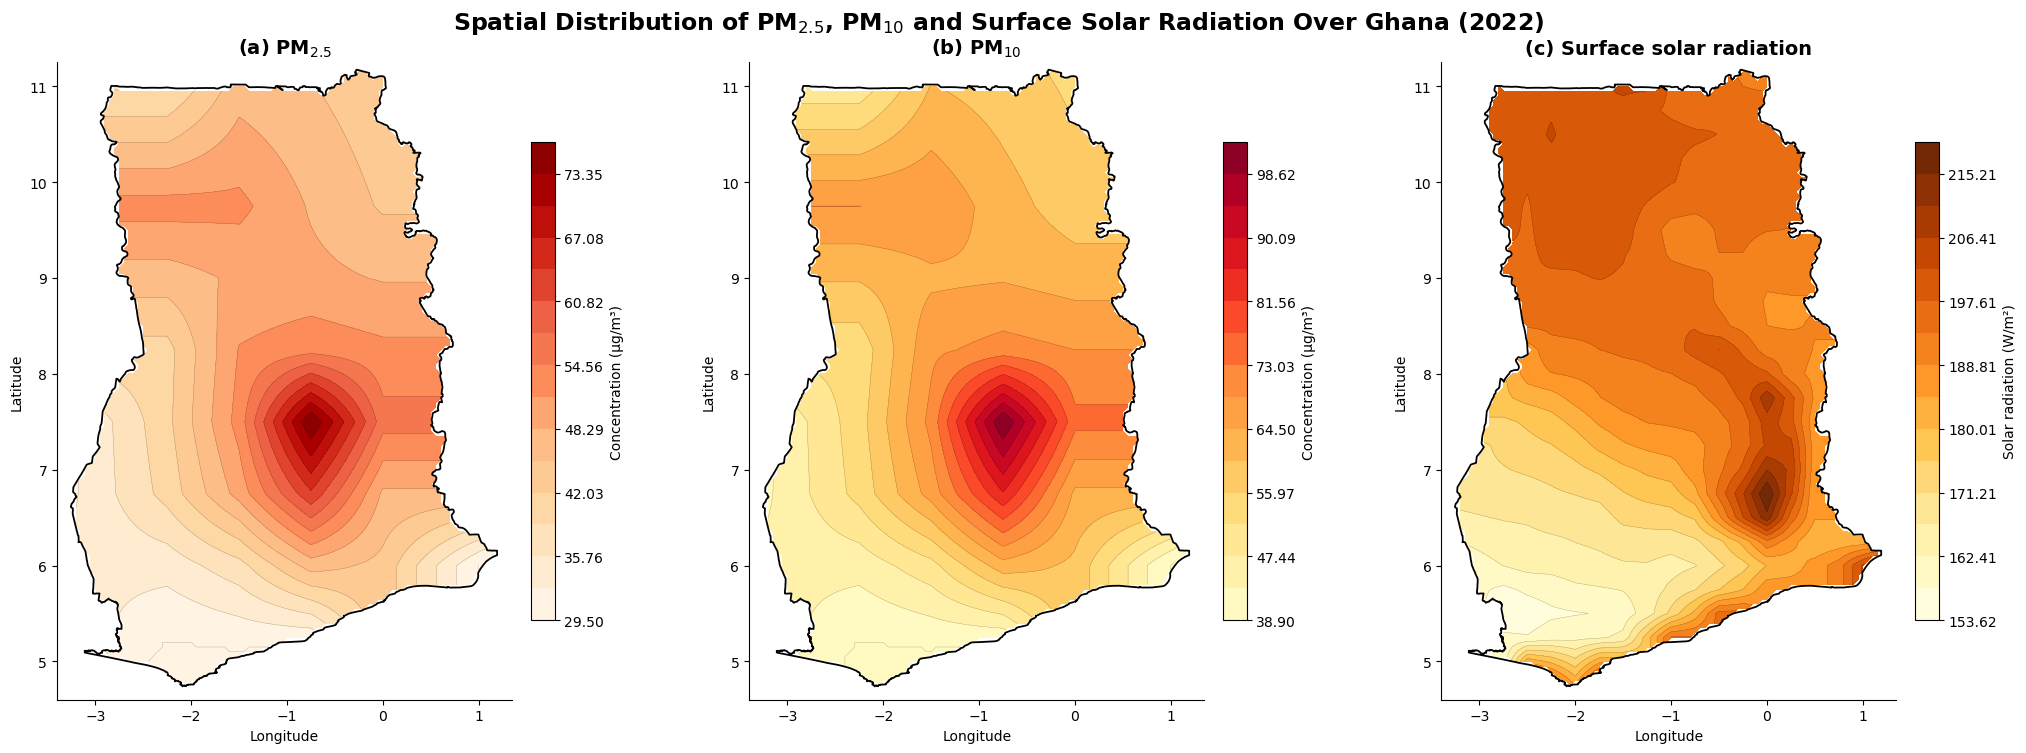

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from scipy import ndimage
from scipy.interpolate import RegularGridInterpolator

# --- Ghana boundary ---
bx, by = ghana_boundary.exterior.xy
boundary_xy = np.column_stack([bx, by])

# --- Common fine grid (0.05°) ---
lon_f = np.arange(-3.4, 1.4, 0.05)
lat_f = np.arange(4.6, 11.3, 0.05)
LON, LAT = np.meshgrid(lon_f, lat_f)

# Mask of points inside Ghana
inside = Path(boundary_xy).contains_points(
    np.column_stack([LON.ravel(), LAT.ravel()])
).reshape(LON.shape)

def fill_nan_nearest(a):
    mask = np.isnan(a)
    if not mask.any():
        return a
    idx = ndimage.distance_transform_edt(mask, return_distances=False, return_indices=True)
    return a[tuple(idx)]

def to_fine_grid(da):
    """Keep this variable's valid cells, then interpolate onto the common fine grid."""
    da = da.dropna("latitude", how="all").dropna("longitude", how="all")
    da = da.sortby("latitude").sortby("longitude")
    vals = fill_nan_nearest(da.values)
    f = RegularGridInterpolator(
        (da.latitude.values, da.longitude.values), vals,
        method="linear", bounds_error=False, fill_value=None)   # None = extrapolate to the border
    out = f(np.column_stack([LAT.ravel(), LON.ravel()])).reshape(LAT.shape)
    out = np.clip(out, vals.min(), vals.max())                  # no overshoot
    return np.where(inside, out, np.nan)                        # blank outside Ghana

pm25 = to_fine_grid(ghana_annual["pm2p5"])
pm10 = to_fine_grid(ghana_annual["pm10"])
ssr  = to_fine_grid(ghana_annual["ssr"])

# --- One figure, three contour panels ---
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))

panels = [
    (pm25, "OrRd", "(a) PM$_{2.5}$",                "Concentration (µg/m³)"),
    (pm10, "YlOrRd", "(b) PM$_{10}$",                 "Concentration (µg/m³)"),
    (ssr,  "YlOrBr", "(c) Surface solar radiation",   "Solar radiation (W/m²)"),
]

for ax, (field, cmap, title, label) in zip(axes, panels):
    levels = np.linspace(np.nanmin(field), np.nanmax(field), 16)
    cf = ax.contourf(LON, LAT, field, levels=levels, cmap=cmap)
    ax.contour(LON, LAT, field, levels=levels, colors="k", linewidths=0.25, alpha=0.35)
    ax.plot(bx, by, color="black", linewidth=1.3, zorder=3)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_aspect("equal")
    cb = fig.colorbar(cf, ax=ax, shrink=0.75, pad=0.03)
    cb.set_label(label)

fig.suptitle("Spatial Distribution of PM$_{2.5}$, PM$_{10}$ and Surface Solar Radiation Over Ghana (2022)",
             fontsize=17, fontweight="bold")
plt.tight_layout()
plt.savefig("Ghana_Combined_Spatial_Distribution_2022.png", dpi=300, bbox_inches="tight")
plt.show()

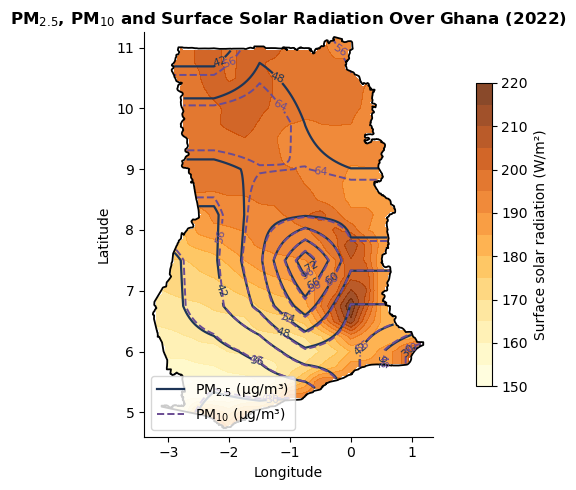

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

cf = ax.contourf(LON, LAT, ssr, levels=15, cmap="YlOrBr", alpha=0.85)
c1 = ax.contour(LON, LAT, pm25, levels=8, colors="#1d3557", linewidths=1.6)
c2 = ax.contour(LON, LAT, pm10, levels=8, colors="#6a4c93", linewidths=1.4, linestyles="--")
ax.clabel(c1, fmt="%d", fontsize=8)
ax.clabel(c2, fmt="%d", fontsize=8)
ax.plot(bx, by, color="black", linewidth=1.3)

fig.colorbar(cf, ax=ax, shrink=0.75).set_label("Surface solar radiation (W/m²)")
ax.plot([], [], color="#1d3557", lw=1.6, label="PM$_{2.5}$ (µg/m³)")
ax.plot([], [], color="#6a4c93", lw=1.4, ls="--", label="PM$_{10}$ (µg/m³)")
ax.legend(loc="lower left", frameon=True)
ax.set_aspect("equal"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("PM$_{2.5}$, PM$_{10}$ and Surface Solar Radiation Over Ghana (2022)", fontweight="bold")
plt.tight_layout(); plt.show()

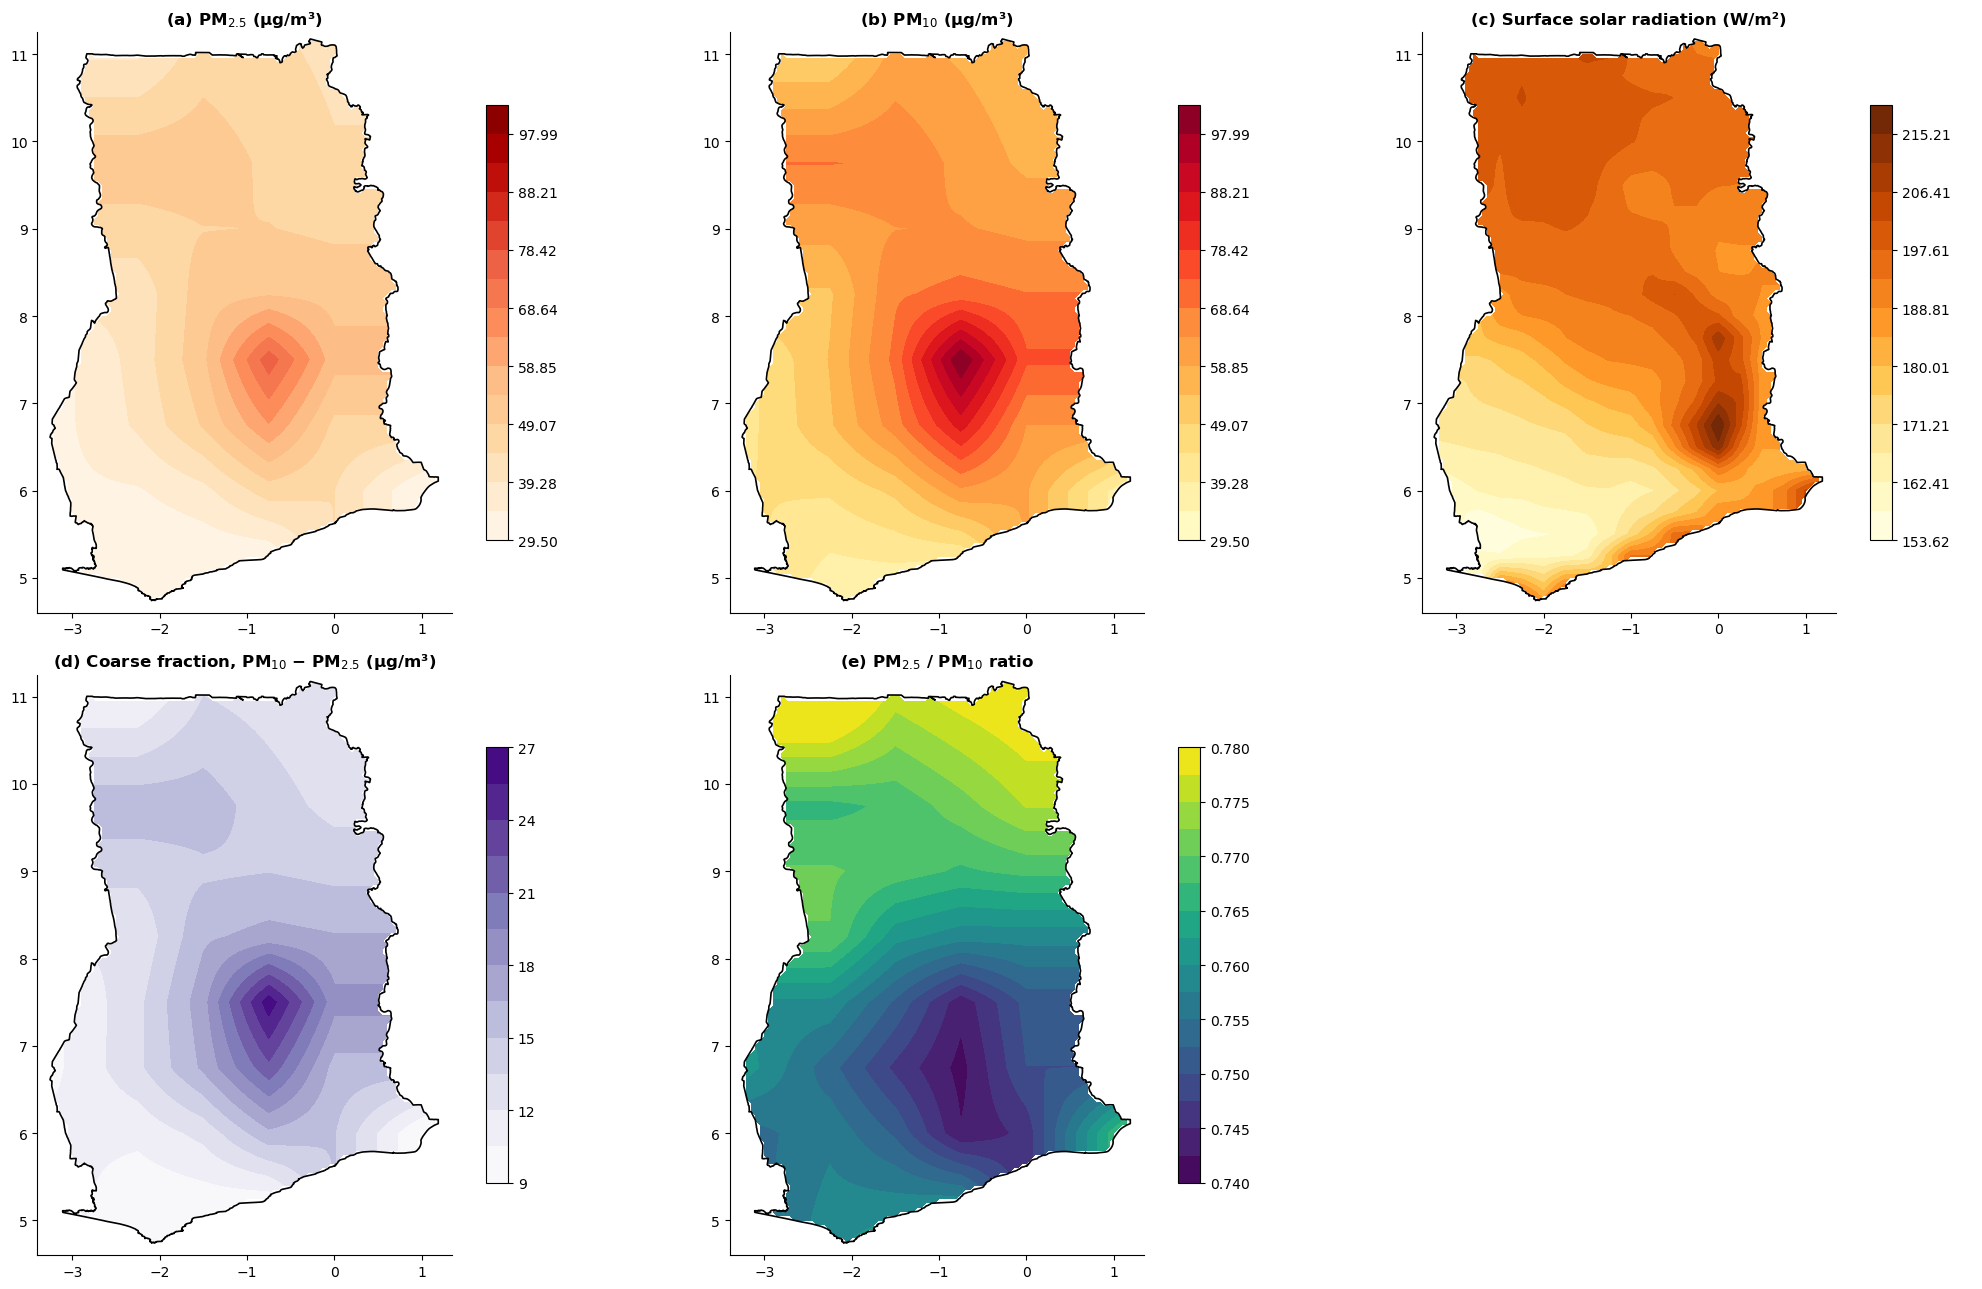

In [26]:
coarse = to_fine_grid(ghana_annual["pm10"] - ghana_annual["pm2p5"])   # PM10 - PM2.5
ratio  = to_fine_grid(ghana_annual["pm2p5"] / ghana_annual["pm10"])

vmin = min(np.nanmin(pm25), np.nanmin(pm10)); vmax = max(np.nanmax(pm25), np.nanmax(pm10))
lv_pm = np.linspace(vmin, vmax, 16)

fig, axes = plt.subplots(2, 3, figsize=(21, 13))
specs = [
    (axes[0,0], pm25,   lv_pm,                              "OrRd", "(a) PM$_{2.5}$ (µg/m³)"),
    (axes[0,1], pm10,   lv_pm,                              "YlOrRd", "(b) PM$_{10}$ (µg/m³)"),
    (axes[0,2], ssr,    np.linspace(np.nanmin(ssr), np.nanmax(ssr), 16), "YlOrBr", "(c) Surface solar radiation (W/m²)"),
    (axes[1,0], coarse, 14,                                 "Purples", "(d) Coarse fraction, PM$_{10}$ − PM$_{2.5}$ (µg/m³)"),
    (axes[1,1], ratio,  14,                                 "viridis", "(e) PM$_{2.5}$ / PM$_{10}$ ratio"),
]
for ax, f, lv, cm, t in specs:
    cf = ax.contourf(LON, LAT, f, levels=lv, cmap=cm)
    ax.plot(bx, by, "k", lw=1.2); ax.set_aspect("equal"); ax.set_title(t, fontweight="bold")
    fig.colorbar(cf, ax=ax, shrink=0.75)
axes[1,2].axis("off")
plt.tight_layout(); plt.show()

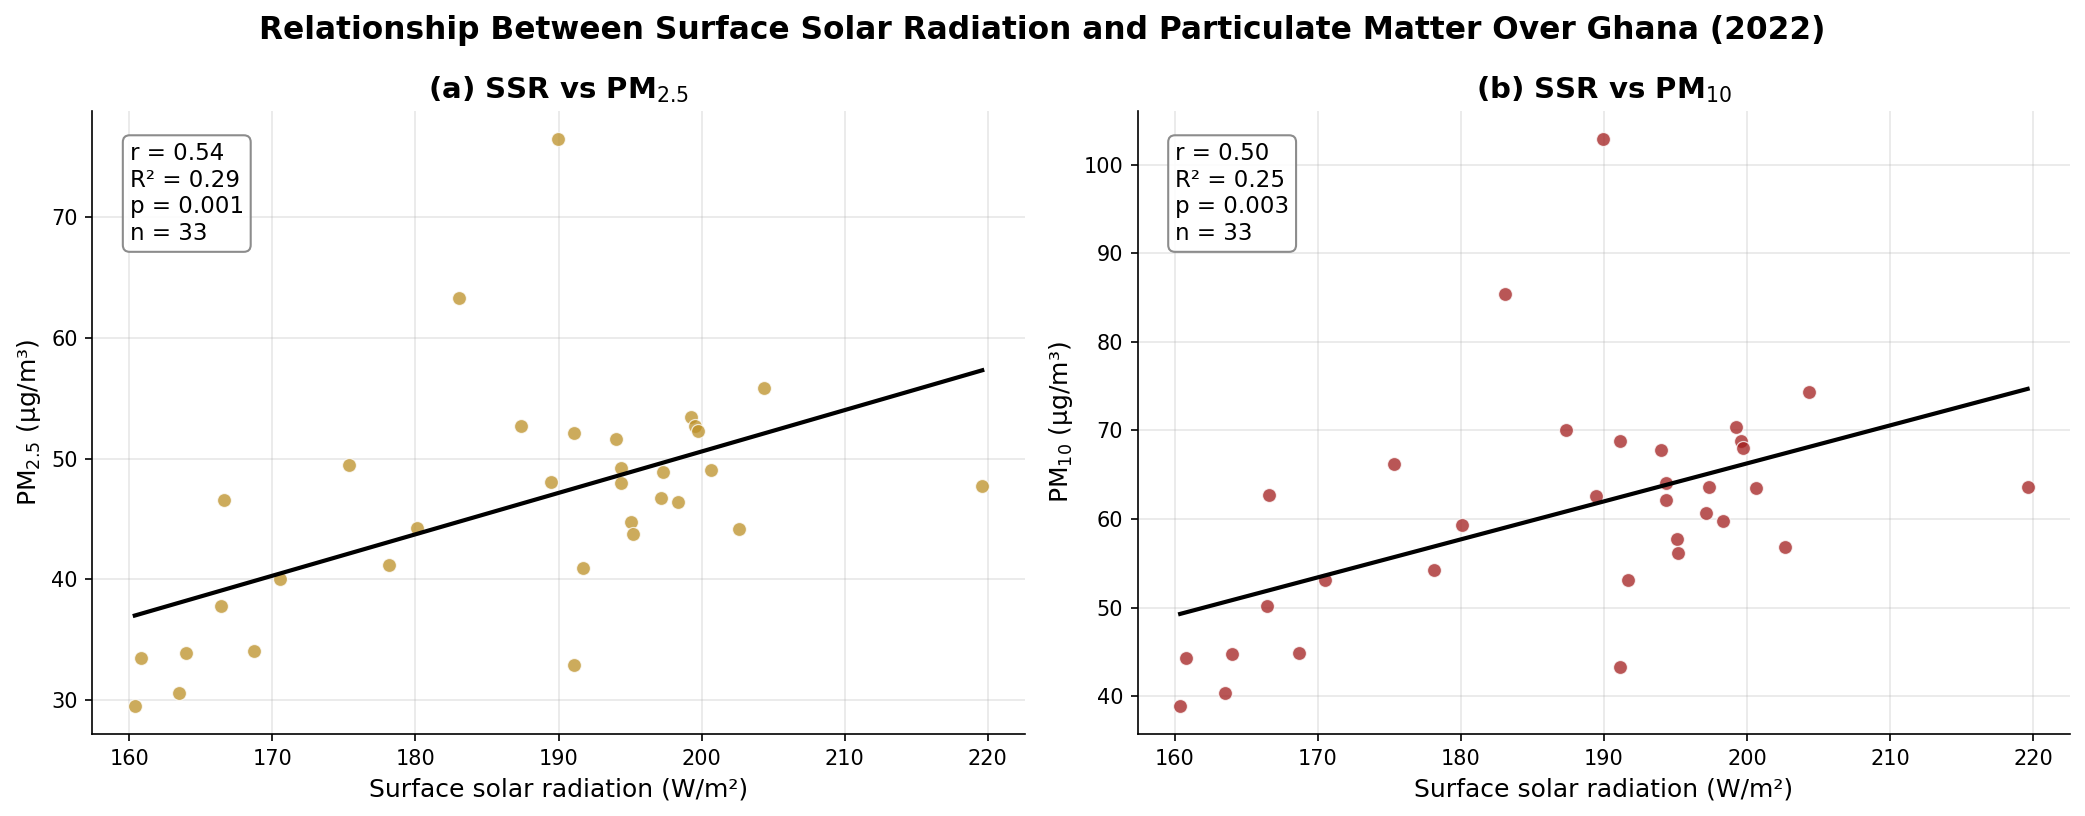

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Cells where all three variables are valid
pm25 = ghana_annual["pm2p5"].values.ravel()
pm10 = ghana_annual["pm10"].values.ravel()
ssr  = ghana_annual["ssr"].values.ravel()
ok = ~np.isnan(pm25) & ~np.isnan(pm10) & ~np.isnan(ssr)
pm25, pm10, ssr = pm25[ok], pm10[ok], ssr[ok]

def scatter_panel(ax, x, y, ylabel, color, title):
    res = stats.linregress(x, y)
    ax.scatter(x, y, s=45, color=color, alpha=0.75,
               edgecolor="white", linewidth=0.6, zorder=3)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, res.intercept + res.slope * xx, color="black",
            linewidth=2, zorder=4)
    p_txt = "p < 0.001" if res.pvalue < 0.001 else f"p = {res.pvalue:.3f}"
    ax.text(0.04, 0.95,
            f"r = {res.rvalue:.2f}\nR² = {res.rvalue**2:.2f}\n{p_txt}\nn = {len(x)}",
            transform=ax.transAxes, va="top", fontsize=11,
            bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))
    ax.set_xlabel("Surface solar radiation (W/m²)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)
scatter_panel(axes[0], ssr, pm25, "PM$_{2.5}$ (µg/m³)", "#bc8f26", "(a) SSR vs PM$_{2.5}$")
scatter_panel(axes[1], ssr, pm10, "PM$_{10}$ (µg/m³)",  "#a21d1d", "(b) SSR vs PM$_{10}$")
fig.suptitle("Relationship Between Surface Solar Radiation and Particulate Matter Over Ghana (2022)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("scatter_ssr_pm_ghana_2022.png", dpi=300, bbox_inches="tight")
plt.show()

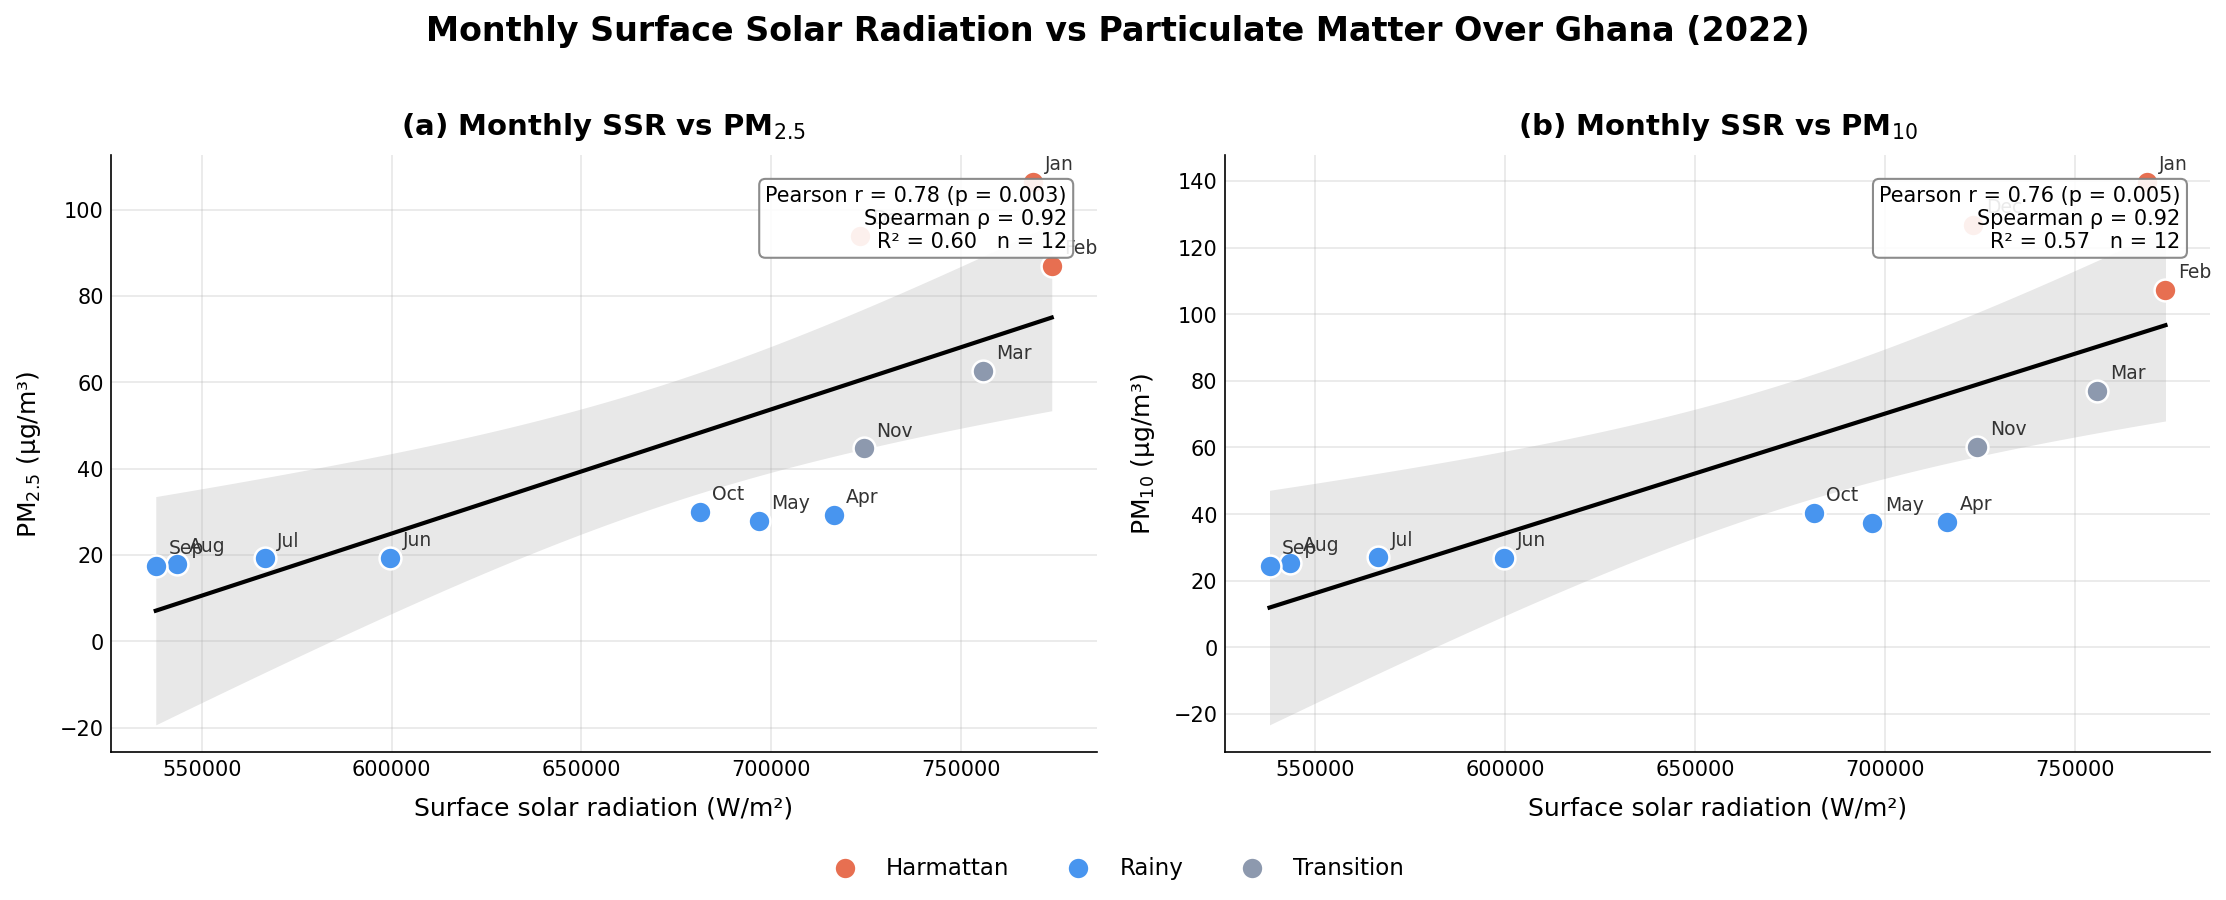

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# --- Data (check the SSR column name with df_monthly.columns) ---
ssr_col = "ssr"
months  = df_monthly["Month_Name"].astype(str).str[:3].values

season_of = {"Dec": "Harmattan", "Jan": "Harmattan", "Feb": "Harmattan",
             "Apr": "Rainy", "May": "Rainy", "Jun": "Rainy", "Jul": "Rainy",
             "Aug": "Rainy", "Sep": "Rainy", "Oct": "Rainy",
             "Mar": "Transition", "Nov": "Transition"}
season_color = {"Harmattan": "#e76f51", "Rainy": "#4895ef", "Transition": "#8d99ae"}
seasons = np.array([season_of[m] for m in months])

def scatter_panel(ax, x, y, ylabel, title):
    res = stats.linregress(x, y)
    rho, p_rho = stats.spearmanr(x, y)

    # Regression line + 95% confidence band
    xx = np.linspace(x.min(), x.max(), 200)
    yy = res.intercept + res.slope * xx
    n = len(x)
    s_err = np.sqrt(np.sum((y - (res.intercept + res.slope * x))**2) / (n - 2))
    t = stats.t.ppf(0.975, n - 2)
    ci = t * s_err * np.sqrt(1/n + (xx - x.mean())**2 / np.sum((x - x.mean())**2))
    ax.fill_between(xx, yy - ci, yy + ci, color="gray", alpha=0.18, lw=0, zorder=1)
    ax.plot(xx, yy, color="black", lw=2, zorder=2)

    # Points coloured by season
    for s, c in season_color.items():
        m = seasons == s
        ax.scatter(x[m], y[m], s=110, color=c, edgecolor="white",
                   linewidth=1.2, zorder=3, label=s)

    # Month labels
    for xi, yi, lab in zip(x, y, months):
        ax.annotate(lab, (xi, yi), xytext=(6, 6), textcoords="offset points",
                    fontsize=9, color="#333333")

    p_txt = "p < 0.001" if res.pvalue < 0.001 else f"p = {res.pvalue:.3f}"
    ax.text(0.97, 0.95,
            f"Pearson r = {res.rvalue:.2f} ({p_txt})\n"
            f"Spearman ρ = {rho:.2f}\n"
            f"R² = {res.rvalue**2:.2f}   n = {n}",
            transform=ax.transAxes, va="top", ha="right", fontsize=10,
            bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))

    ax.set_xlabel("Surface solar radiation (W/m²)", fontsize=12, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=12, labelpad=8)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(length=0)

plt.rcParams.update({"font.family": "DejaVu Sans"})
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

scatter_panel(axes[0], df_monthly[ssr_col].values, df_monthly["pm2p5_ugm3"].values,
              "PM$_{2.5}$ (µg/m³)", "(a) Monthly SSR vs PM$_{2.5}$")
scatter_panel(axes[1], df_monthly[ssr_col].values, df_monthly["pm10_ugm3"].values,
              "PM$_{10}$ (µg/m³)", "(b) Monthly SSR vs PM$_{10}$")

# One shared legend below the panels
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=11)

fig.suptitle("Monthly Surface Solar Radiation vs Particulate Matter Over Ghana (2022)",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.savefig("scatter_ssr_pm_monthly_ghana_2022.png", dpi=300, bbox_inches="tight")
plt.show()

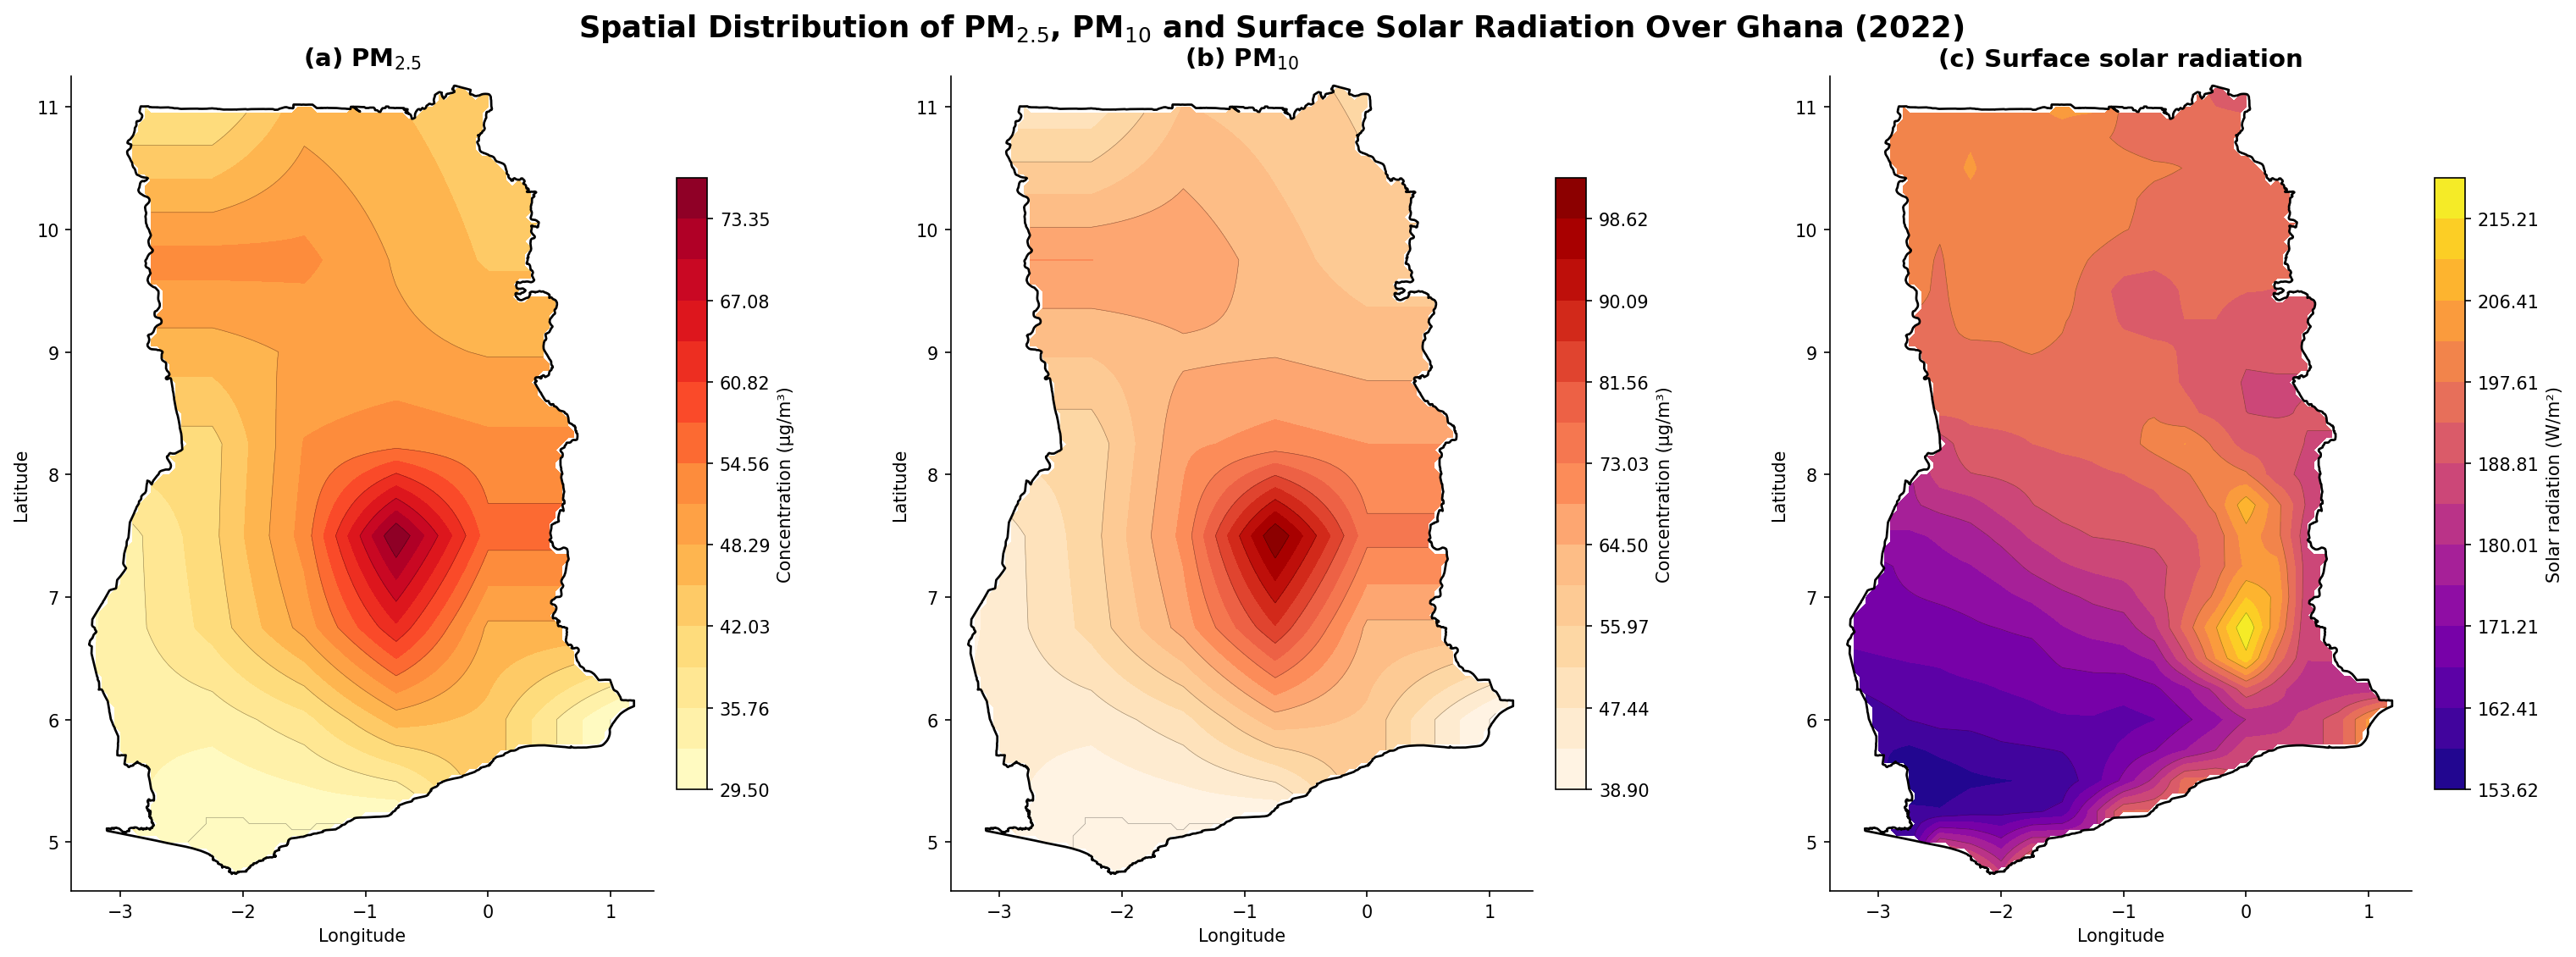

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from scipy import ndimage
from scipy.interpolate import RegularGridInterpolator

# --- Ghana boundary ---
bx, by = ghana_boundary.exterior.xy
boundary_xy = np.column_stack([bx, by])

# --- Common fine grid (0.05°) ---
lon_f = np.arange(-3.4, 1.4, 0.05)
lat_f = np.arange(4.6, 11.3, 0.05)
LON, LAT = np.meshgrid(lon_f, lat_f)

# Mask of points inside Ghana
inside = Path(boundary_xy).contains_points(
    np.column_stack([LON.ravel(), LAT.ravel()])
).reshape(LON.shape)

def fill_nan_nearest(a):
    mask = np.isnan(a)
    if not mask.any():
        return a
    idx = ndimage.distance_transform_edt(mask, return_distances=False, return_indices=True)
    return a[tuple(idx)]

def to_fine_grid(da):
    """Keep this variable's valid cells, then interpolate onto the common fine grid."""
    da = da.dropna("latitude", how="all").dropna("longitude", how="all")
    da = da.sortby("latitude").sortby("longitude")
    vals = fill_nan_nearest(da.values)
    f = RegularGridInterpolator(
        (da.latitude.values, da.longitude.values), vals,
        method="linear", bounds_error=False, fill_value=None)
    out = f(np.column_stack([LAT.ravel(), LON.ravel()])).reshape(LAT.shape)
    out = np.clip(out, vals.min(), vals.max())
    return np.where(inside, out, np.nan)

pm25 = to_fine_grid(ghana_annual["pm2p5"])
pm10 = to_fine_grid(ghana_annual["pm10"])
ssr  = to_fine_grid(ghana_annual["ssr"])

# --- One figure, three contour panels, a different colormap for each ---
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5), dpi=150)

panels = [
    (pm25, "YlOrRd", "(a) PM$_{2.5}$",              "Concentration (µg/m³)"),
    (pm10, "OrRd",   "(b) PM$_{10}$",               "Concentration (µg/m³)"),
    (ssr,  "plasma", "(c) Surface solar radiation", "Solar radiation (W/m²)"),
]

for ax, (field, cmap, title, label) in zip(axes, panels):
    levels = np.linspace(np.nanmin(field), np.nanmax(field), 16)
    cf = ax.contourf(LON, LAT, field, levels=levels, cmap=cmap)
    ax.contour(LON, LAT, field, levels=levels[::2], colors="k",
               linewidths=0.3, alpha=0.4)
    ax.plot(bx, by, color="black", linewidth=1.3, zorder=3)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")
    ax.spines[["top", "right"]].set_visible(False)
    cb = fig.colorbar(cf, ax=ax, shrink=0.75, pad=0.03)
    cb.set_label(label)

fig.suptitle("Spatial Distribution of PM$_{2.5}$, PM$_{10}$ and Surface Solar Radiation Over Ghana (2022)",
             fontsize=17, fontweight="bold")
plt.tight_layout()
plt.savefig("Ghana_Combined_Spatial_Distribution_2022.png", dpi=300, bbox_inches="tight")
plt.show()

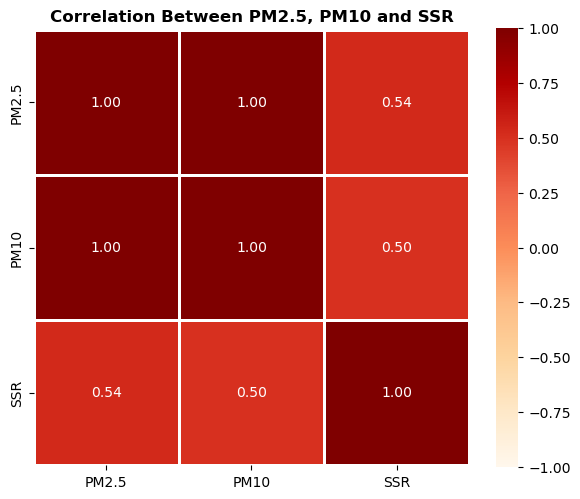

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

df_corr = (ghana_annual.reset_coords(drop=True)[["pm2p5", "pm10", "ssr"]]
           .to_dataframe().dropna()
           .rename(columns={"pm2p5": "PM2.5", "pm10": "PM10", "ssr": "SSR"}))

plt.figure(figsize=(6, 5))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="OrRd",
            vmin=-1, vmax=1, square=True, linewidths=1)
plt.title("Correlation Between PM2.5, PM10 and SSR")
plt.tight_layout()
plt.savefig("Ghana_correlation_simple.png", dpi=300, bbox_inches="tight")
plt.show()